# ЛР № 3. Формирование проектных команд

Вариант 14

Набираю три команды из 12 кандидатов. В каждой нужен руководитель, разработчик и аналитик. Некоторые пары не могут работать вместе.

**Среда выполнения → Выполнить всё** запускает весь расчёт.

In [1]:
%pip install -q numpy==2.3.5 scipy==1.17.0 matplotlib==3.10.8

## Данные

Роли идут по кругу, затраты сгенерированы целыми. Несовместимые пары для первых 12 кандидатов заданы шаблоном. Полные данные нужны для замеров на большем масштабе.

Читаю `data.json`. Если файла нет, создаю его с `seed=10011`.

In [2]:
import csv
import json
import os
from contextlib import redirect_stderr, redirect_stdout
from ctypes import CDLL
from pathlib import Path
from itertools import combinations, product
from time import perf_counter
from io import BytesIO

import numpy as np
from IPython.display import Markdown, display
from IPython.display import Image
from scipy.optimize import Bounds, LinearConstraint, linprog, milp
from scipy.sparse import lil_matrix

SEED = 10011
TOL = 1e-7
STATUS = {0: "optimal", 1: "limit", 2: "infeasible", 3: "unbounded", 4: "solver_error"}

LAB_DIR = Path.cwd()
if LAB_DIR.name != "lr3":
    LAB_DIR = LAB_DIR / "lr3"
DATA_PATH = LAB_DIR / "data.json"
RESULTS = LAB_DIR / "results"


def teams(rng):
    count, team_count = 72, 18
    roles = np.arange(count) % 3
    fees = rng.integers(7, 21, count)
    assignment = rng.integers(12, 65, (count, team_count))
    conflicts = [(1, 2), (1, 3), (2, 6), (4, 5), (5, 9), (7, 8), (8, 12), (10, 11), (1, 6), (2, 10)]
    for i in range(1, count + 1):
        for j in range(max(i + 1, 13), min(i + 15, count + 1)):
            if roles[i - 1] != roles[j - 1] and rng.random() < 0.13:
                conflicts.append((i, j))
    return {
        "seed": SEED, "roles": roles.tolist(),
        "role_names": ["Руководитель", "Разработчик", "Аналитик"],
        "fee": fees.tolist(), "assignment_cost": assignment.tolist(),
        "conflicts": conflicts,
    }


if not DATA_PATH.is_file():
    LAB_DIR.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(np.random.SeedSequence([SEED, 3]))
    DATA_PATH.write_text(
        json.dumps(teams(rng), ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
data = json.loads(DATA_PATH.read_text(encoding="utf-8"))

## Решатель и файлы

HiGHS решает модель. Таблицы и лог записываются в `results`.

In [3]:
def write_csv(folder, name, headers, rows):
    path = folder / f"{name}.csv"
    path.parent.mkdir(exist_ok=True)
    with path.open("w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(headers)
        writer.writerows(rows)


def write_check(folder, name, result):
    path = folder / f"{name}.json"
    path.write_text(json.dumps(result, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")


def solve_lp(cost, *, label, verbose=True, **kwargs):
    print(f"\n=== {label} ===", flush=True)
    result = linprog(
        cost, method="highs-ds", options={"presolve": True, "disp": verbose}, **kwargs
    )
    print(f"{STATUS.get(result.status, result.status)} | {result.message}", flush=True)
    return result


def require_status(result, *allowed):
    if result.status not in allowed:
        raise RuntimeError(result.message)


def run_with_log(run, data, folder):
    folder.mkdir(parents=True, exist_ok=True)
    with (folder / "solver.log").open("w", encoding="utf-8", buffering=1) as log:
        # HiGHS пишет лог напрямую в stdout, минуя Python.
        stdout_fd = os.dup(1)
        try:
            os.dup2(log.fileno(), 1)
            with redirect_stdout(log), redirect_stderr(log):
                return run(data)
        finally:
            CDLL(None).fflush(None)
            os.dup2(stdout_fd, 1)
            os.close(stdout_fd)


def show_table(path, columns, labels=None, *, scenario=None):
    names = {"optimal": "Оптимум", "infeasible": "Нет допустимого плана",
             "feasible": "Допустим", **(labels or {})}
    with path.open(encoding="utf-8", newline="") as file:
        rows = [[row[key] for key in columns] for row in csv.DictReader(file)
                if scenario is None or row["scenario"] == scenario]

    def format_cell(value):
        if not value:
            return "—"
        try:
            number = float(value)
        except ValueError:
            return names.get(value, value)
        return f"{number:,.3f}".rstrip("0").rstrip(".").replace(",", " ").replace(".", ",")

    table = [list(columns.values()), ["---"] * len(columns)]
    table += [[format_cell(value) for value in row] for row in rows]
    display(Markdown("\n".join("| " + " | ".join(row) + " |" for row in table)))

## Модель

У каждого кандидата есть признак участия в проекте и отдельный признак назначения в каждую команду. Выбранный кандидат занимает одну роль в одной команде.

In [4]:
def inputs(data, count, teams):
    roles = np.array(data["roles"][:count])
    fee = np.array(data["fee"][:count])
    cost = np.array(data["assignment_cost"])[:count, :teams]
    pairs = np.array([pair for pair in data["conflicts"] if max(pair) <= count]) - 1
    return roles, fee, cost, pairs


def build_model(roles, fee, cost, pairs, unavailable=(), multiplier=1):
    count, teams = cost.shape
    size = cost.size
    assign = np.arange(size).reshape(count, teams)
    chosen = size + np.arange(count)
    equality = lil_matrix((3 * teams, size + count))
    rows = lil_matrix((3 * count + len(pairs) * teams, size + count))
    for t in range(teams):
        for role in range(3):
            equality[3 * t + role, assign[roles == role, t]] = 1
    for i in range(count):
        rows[i, assign[i]] = 1
        rows[count + i, assign[i]] = 1
        rows[count + i, chosen[i]] = -multiplier
        rows[2 * count + i, assign[i]] = -1
        rows[2 * count + i, chosen[i]] = 1
    for p, (i, j) in enumerate(pairs):
        for t in range(teams):
            rows[3 * count + p * teams + t, [assign[i, t], assign[j, t]]] = 1
    upper = np.ones(size + count)
    for i in unavailable:
        upper[assign[i]] = 0
        upper[chosen[i]] = 0
    return {"cost": np.r_[cost.ravel(), fee], "upper": upper,
            "A_eq": equality.tocsr(), "b_eq": np.ones(3 * teams),
            "A_ub": rows.tocsr(), "b_ub": np.r_[np.ones(count), np.zeros(2 * count),
                                              np.ones(len(pairs) * teams)]}


def solve_milp(model, label, *, time_limit=None, verbose=True):
    options = {"presolve": True, "mip_rel_gap": 0, "disp": verbose}
    if time_limit is not None:
        options["time_limit"] = time_limit
    bounds = Bounds(0, model["upper"])
    constraints = [LinearConstraint(model["A_eq"], model["b_eq"], model["b_eq"]),
                   LinearConstraint(model["A_ub"], -np.inf, model["b_ub"])]
    print(f"\n=== {label} ===", flush=True)
    start = perf_counter()
    result = milp(model["cost"], integrality=np.ones(len(model["cost"])), bounds=bounds,
                  constraints=constraints, options=options)
    elapsed = perf_counter() - start
    print(f"{STATUS.get(result.status, result.status)} | {result.message} | {elapsed:.6f} s",
          flush=True)
    return result, elapsed


def relaxation(model, label):
    return solve_lp(model["cost"], label=label, A_ub=model["A_ub"], b_ub=model["b_ub"],
                    A_eq=model["A_eq"], b_eq=model["b_eq"],
                    bounds=np.column_stack((np.zeros(len(model["cost"])), model["upper"])))


def unpack(vector, shape):
    size = np.prod(shape)
    return vector[:size].reshape(shape), vector[size:]

## Проверка плана

В NumPy отдельно проверяю ограничения и пересчитываю стоимость. Допуск — $10^{-7}$.

In [5]:
def max_violation(values):
    return float(np.max(values, initial=0))


def verify_objective(checks, expected, actual):
    checks["objective_recomputed"] = float(actual)
    checks["objective_error"] = float(abs(expected - actual))
    if any(value > TOL for key, value in checks.items() if key != "objective_recomputed"):
        raise ValueError(f"Independent check failed: {checks}")
    return checks


def cost_of(x, y, fee, cost):
    return np.sum(x * cost) + fee @ y


def verify(x, y, roles, fee, cost, pairs, unavailable, objective, *, multiplier=1, integral=True):
    counts = x.sum(axis=1)
    checks = {
        "role_balance": max(max_violation(abs(x[roles == role].sum(axis=0) - 1))
                            for role in range(3)),
        "one_team": max_violation(counts - 1),
        "activation": max_violation(counts - multiplier * y),
        "no_unused_hires": max_violation(y - counts),
        "incompatible_pairs": max_violation(x[pairs[:, 0]] + x[pairs[:, 1]] - 1),
        "bounds": max(max_violation(-x), max_violation(x - 1),
                      max_violation(-y), max_violation(y - 1)),
        "unavailable": max(max_violation(abs(x[list(unavailable)])),
                           max_violation(abs(y[list(unavailable)]))),
    }
    if integral:
        checks["integrality"] = max(max_violation(abs(x - np.rint(x))),
                                    max_violation(abs(y - np.rint(y))))
        checks["hire_exactness"] = max_violation(abs(counts - y))
    return verify_objective(checks, objective, cost_of(x, y, fee, cost))


def greedy(roles, fee, cost, pairs):
    unavailable = set()
    forbidden = {tuple(pair) for pair in pairs}
    by_role = [np.flatnonzero(roles == role) for role in range(3)]
    x = np.zeros_like(cost, dtype=float)
    for t in range(cost.shape[1]):
        choices = []
        for group in product(*by_role):
            if unavailable.intersection(group):
                continue
            if any(pair in forbidden for pair in combinations(sorted(group), 2)):
                continue
            choices.append((sum(fee[i] + cost[i, t] for i in group), group))
        _, group = min(choices)
        x[list(group), t] = 1
        unavailable.update(group)
    return x, x.sum(axis=1)


def benchmark(data):
    samples, summary = [], []
    for count, teams in [(12, 3), (24, 6), (48, 12), (72, 18)]:
        args = inputs(data, count, teams)
        model = build_model(*args)
        timings, gaps, statuses = [], [], []
        for repeat in range(1, 4):
            result, elapsed = solve_milp(model, f"scale {count} #{repeat}", time_limit=1,
                                         verbose=(repeat == 1))
            require_status(result, 0, 1)
            gap = None
            if result.x is not None:
                verify(*unpack(result.x, args[2].shape), *args, (), result.fun)
                if result.mip_gap is not None:
                    gap = 100 * result.mip_gap
                    gaps.append(gap)
            timings.append(elapsed)
            statuses.append(STATUS[result.status])
            samples.append([count, teams, len(model["cost"]), repeat, statuses[-1], elapsed,
                            gap, result.fun, result.mip_dual_bound, result.mip_node_count])
        summary.append([count, teams, len(model["cost"]), np.median(timings),
                        np.median(gaps) if gaps else None, statuses.count("optimal")])
    write_csv(RESULTS, "scaling_runs", ["candidates", "teams", "binaries", "repeat", "status",
                                     "seconds", "gap_pct", "objective", "dual_bound", "nodes"], samples)
    write_csv(RESULTS, "scaling", ["candidates", "teams", "binaries", "median_seconds",
                                "median_gap_pct", "optimal_runs"], summary)
    return np.array(summary, dtype=float)


def draw_benchmark(summary):
    import matplotlib.pyplot as plt

    fig, axes = plt.subplots(1, 2, figsize=(6.6, 2.8), layout="constrained")
    count = summary[:, 0].astype(int)
    for ax, metric, label in zip(axes, [summary[:, 3], summary[:, 4]],
                                 ["Медиана времени, с", "Медиана зазора, %"]):
        ax.plot(count, metric, "o-", color="#222222", linewidth=1.25, markersize=4, clip_on=False)
        ax.set_xticks(count)
        ax.set(xlabel="Кандидаты", ylabel=label, ylim=(0, None))
        ax.grid(axis="y", color="#d9d9d9", linewidth=0.65)
        for edge in ["top", "right"]:
            ax.spines[edge].set_visible(False)
    fig.savefig(RESULTS / "scaling.pdf")
    plt.close(fig)
    return fig

## Что меняю в сценариях

По очереди убираю кандидатов 1 и 2. Сравниваю целочисленный и жадный планы, а также LP-релаксации при обычном и завышенном $M$.

In [6]:
def run_lab(data):
    roles, fee, cost, pairs = inputs(data, 12, 3)
    args = roles, fee, cost, pairs
    runs, checks, plans = [], {}, []
    base = build_model(*args)
    for name, unavailable in [("base", ()), ("deficit", (0,)), ("stress", (0, 1))]:
        model = base if not unavailable else build_model(*args, unavailable)
        result, elapsed = solve_milp(model, f"{name} MILP")
        require_status(result, 0)
        runs.append((name, "optimal", result.fun, elapsed, result.mip_gap, result.mip_dual_bound,
                     result.mip_node_count, unpack(result.x, cost.shape), unavailable, 1, True))

    loose = build_model(*args, multiplier=1000)
    for name, model, factor in [("base_lp", base, 1), ("loose_lp", loose, 1000)]:
        result = relaxation(model, name)
        require_status(result, 0)
        runs.append((name, "optimal", result.fun, None, None, None, None,
                     unpack(result.x, cost.shape), (), factor, False))
    result, elapsed = solve_milp(loose, "loose MILP")
    require_status(result, 0)
    runs.append(("loose_milp", "optimal", result.fun, elapsed, result.mip_gap,
                 result.mip_dual_bound, result.mip_node_count, unpack(result.x, cost.shape),
                 (), 1000, True))

    start = perf_counter()
    x, y = greedy(*args)
    elapsed = perf_counter() - start
    runs.append(("greedy", "feasible", cost_of(x, y, fee, cost), elapsed, None, None, None,
                 (x, y), (), 1, True))
    summary = []
    for name, status, value, elapsed, gap, bound, nodes, plan, unavailable, factor, integral in runs:
        x, y = plan
        checks[name] = verify(x, y, *args, unavailable, value, multiplier=factor, integral=integral)
        summary.append([name, status, value, elapsed, gap, bound, nodes,
                        np.sum(x * cost), fee @ y])
        for i in range(len(roles)):
            plans.append([name, i + 1, data["role_names"][roles[i]], *x[i], y[i]])
    write_csv(RESULTS, "scenarios", ["scenario", "status", "cost", "seconds", "mip_gap_fraction",
                                   "dual_bound", "nodes", "assignment_cost", "hiring_cost"], summary)
    write_csv(RESULTS, "solution", ["scenario", "candidate", "role", "team_1", "team_2", "team_3",
                                   "hired"], plans)
    write_check(RESULTS, "checks", checks)
    return draw_benchmark(benchmark(data))


figure = run_with_log(run_lab, data, RESULTS)

## Что получилось

В первой таблице собраны затраты по сценариям, дальше — замеры для разных размеров задачи. Полные составы команд и LP-план записаны в `solution.csv`.

| План | Статус | Стоимость, тыс. руб. |
| --- | --- | --- |
| Базовый MILP | Оптимум | 366 |
| Дефицит | Оптимум | 389 |
| Стресс | Оптимум | 410 |
| Базовый LP | Оптимум | 358,5 |
| LP с M = 1000 | Оптимум | 242,616 |
| MILP с M = 1000 | Оптимум | 366 |
| Жадный план | Допустим | 388 |

| Кандидатов | Команд | Бинарных переменных | Медиана времени, с | Медиана зазора, % |
| --- | --- | --- | --- | --- |
| 12 | 3 | 48 | 0,002 | 0 |
| 24 | 6 | 168 | 0,003 | 0 |
| 48 | 12 | 624 | 0,009 | 0 |
| 72 | 18 | 1 368 | 0,03 | 0 |

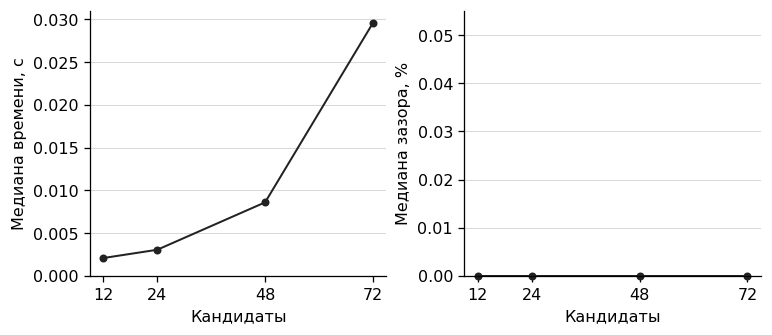

Максимальное расхождение при пересчёте стоимости: 0.


In [7]:
show_table(
    RESULTS / "scenarios.csv",
    {"scenario": "План", "status": "Статус", "cost": "Стоимость, тыс. руб."},
    {"base": "Базовый MILP", "base_lp": "Базовый LP", "loose_lp": "LP с M = 1000",
     "loose_milp": "MILP с M = 1000", "greedy": "Жадный план",
     "deficit": "Дефицит", "stress": "Стресс"},
)
show_table(
    RESULTS / "scaling.csv",
    {"candidates": "Кандидатов", "teams": "Команд", "binaries": "Бинарных переменных",
     "median_seconds": "Медиана времени, с", "median_gap_pct": "Медиана зазора, %"},
)

with BytesIO() as buffer:
    figure.savefig(buffer, format="png", dpi=115, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))

checks = json.loads((RESULTS / "checks.json").read_text(encoding="utf-8"))
error = max(item["objective_error"] for item in checks.values() if "objective_error" in item)
print(f"Максимальное расхождение при пересчёте стоимости: {error:.2g}.")